## Bologna Green Areas Exploration

Layers explored ~ built:
  1. DBSN  ar_vrd   → parks / gardens (types "01", "95")
  2. DBSN  bosco    → woodland / forest patches
  3. DBSN  pe_unis  → uniform open spaces (might include public squares / green)
  4. OSM            → leisure=park / garden

=> Accessibility-eligible criteria (300m rule):
  • publicly accessible  (not private / restricted)


In [1]:
import warnings
warnings.filterwarnings("ignore")

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import osmnx as ox
import fiona
import os
import numpy as np


os.chdir("/Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index")

In [2]:
CRS_WGS    = "EPSG:4326"
CRS_METRIC = "EPSG:32632"

DBSN_GDB = "/Users/terezasaskova/Downloads/BO_dbsn_2025-07-28/Bologna_dbsn.gdb"
OUT_GPKG  = "greenery_all.gpkg"

PRIVATE_ACCESS = {"private", "no", "restricted", "permit", "customers"}

boundary = gpd.read_file("data/bologna_boundary.gpkg").to_crs(CRS_METRIC)
boundary_ha = boundary.geometry.area.sum() / 1e4

In [3]:
def area_ha(gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    #add area_ha column 
    gdf = gdf.copy()
    gdf["area_ha"] = gdf.geometry.area / 1e4
    return gdf

def clip_and_reset(gdf, boundary):
    return gdf.pipe(gpd.clip, boundary).reset_index(drop=True)

def describe_areas(gdf):
    print(f"Features : {len(gdf):,}")
    if "area_ha" in gdf.columns:
        d = gdf["area_ha"].describe().round(0)
        print(f"Area (ha): median={d['50%']}, total={gdf['area_ha'].sum():.1f}")

## DBSN - AREA VERDE (ar_vrd)

- Columns : ['ar_vrd_ty', 'scril', 'meta_ist', 'classid', 'shape_Length', 'shape_Area', 'geometry']
- with the attribute ar_vrd_ty:
01 => not qualified garden
95 => other


In [4]:
ar_vrd = gpd.read_file(DBSN_GDB, layer="ar_vrd").to_crs(CRS_METRIC)
print(f"Total features: {len(ar_vrd):,}")
print(ar_vrd["ar_vrd_ty"].value_counts().to_string())

av_green_areas = (
    ar_vrd
    .query('ar_vrd_ty in ["01", "95"]')   # parks + sport/recreation green
    .pipe(clip_and_reset, boundary)
    .pipe(area_ha)
)
print("ar_vrd: parks+gardens (types 01,95), all sizes:")
describe_areas(av_green_areas)


Total features: 26,279
ar_vrd_ty
01    26231
95       48
ar_vrd: parks+gardens (types 01,95), all sizes:
Features : 3,814
Area (ha): median=0.0, total=3050.0


## DBSN - FOREST (bosco)
- Columns        : ['bosco_gov', 'scril', 'bosco_essz', 'bosco_nom', 'bosco_ty', 'meta_ist', 'classid', 'shape_Length', 'shape_Area', 'geometry']
- bosco_gov: Form of governance / silvicultural management
This is a forestry term describing how the forest is managed:

01 Fustaia = high forest — trees grown from seed to full height, typically older and taller, often more "park-like" in feel
02 Ceduo = coppice — trees regularly cut back and regrow from stumps, usually denser and scrubby, less walkable

For accessibility, fustaia patches are more likely to be pleasant and penetrable; ceduo can be quite dense and unpleasant to walk through.

- bosco_ty:  Forest type (the dominant vegetation structure)
Classifies the forest by its main tree type, following Italy's National Forest Inventory (INFC) categories. So 01 = conifer-dominated, 02 = deciduous-dominated (with subtypes for broad-leaved deciduous vs evergreen), 03 = plantations (human-planted, often commercial), 04 = shrubs and scrub (low vegetation, not really "forest"), 05 = mixed. For your purposes, 04 (shrubs) is probably worth filtering out since it's not what most people think of as accessible green space.

- bosco_ty not in 04 (exclude shrubs/scrub)
- bosco_gov == "01" (fustaia only — more accessible, park-like character)
area ≥ 1 ha

In [5]:
bosco_raw = gpd.read_file(DBSN_GDB, layer="bosco").to_crs(CRS_METRIC)
bosco_clipped = bosco_raw.pipe(clip_and_reset, boundary).pipe(area_ha)

forest = (
    bosco_clipped
    .query('bosco_ty in ["01", "02"]')   # real forest only, exclude 91/95 unknowns
    .pipe(area_ha)                           # recalculate after filter (no re-clip needed)
)
print(f"bosco suitable:")
describe_areas(forest)


bosco suitable:
Features : 173
Area (ha): median=1.0, total=728.9


## DBSN - settlement units (pe_unis)
-   Columns : ['pe_uins_nm', 'pe_uins_ty', 'pe_uins_pa', 'scril', 'meta_ist', 'classid', 'shape_Length', 'shape_Area', 'geometry']
- the attribute pe_uins_ty you can identify: 
- 0301 => schools areas
- 0302 => hospital areas
- 0303 => cemeteries areas
- 04 => military areas
- 06 => industry areas
- 1001 => playgrounds
- 11 => park/garden - public or private
- 1101 => garden
- 1102 =>
- 1103 => park

In [6]:
pe_raw = gpd.read_file(DBSN_GDB, layer="pe_uins").to_crs(CRS_METRIC)
print(f"Total features : {len(pe_raw):,}")

pe_clipped = pe_raw.pipe(clip_and_reset, boundary).pipe(area_ha)
print("pe_unis — all, clipped to Bologna")
describe_areas(pe_clipped)

GREEN_TYPES = ["11", "1001", "1101", "1102", "1103"]  #park/garden/playground 

green_areas = (
    pe_clipped
    .loc[lambda df: df["pe_uins_ty"].isin(GREEN_TYPES)]
    .pipe(area_ha)
)

Total features : 3,794
pe_unis — all, clipped to Bologna
Features : 673
Area (ha): median=0.0, total=1647.6


## OSM - leisure = park / garden

In [7]:
osm_raw = ox.features_from_place("Bologna, Italy", tags={"leisure": ["park", "garden"]})
osm = (
    osm_raw[osm_raw.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]
    .copy()
    .to_crs(CRS_METRIC)
    .pipe(clip_and_reset, boundary)
    .pipe(area_ha)
)
print("OSM parks+gardens — all:")
describe_areas(osm)

# Access filter
osm_parks = osm.loc[
    osm["access"].isna() | ~osm["access"].isin(PRIVATE_ACCESS)
].copy()
print("OSM parks+gardens — public (access not private/restricted)")
describe_areas(osm_parks)



OSM parks+gardens — all:
Features : 1,055
Area (ha): median=0.0, total=1184.4
OSM parks+gardens — public (access not private/restricted)
Features : 1,030
Area (ha): median=0.0, total=1178.6


## SUMMARY COMPARISON


In [8]:
summary = pd.DataFrame([
    {"layer": "DBSN ar_vrd",       "filter": "all parks/gardens",         "n": len(av_green_areas),     "total_ha": av_green_areas.area_ha.sum(),     "pct": av_green_areas.area_ha.sum()/boundary_ha*100},
    {"layer": "DBSN bosco",         "filter": "all",                       "n": len(forest),    "total_ha": forest.area_ha.sum(),    "pct": forest.area_ha.sum()/boundary_ha*100},
    {"layer": "DBSN pe_unis",       "filter": "all",                       "n": len(green_areas),       "total_ha": green_areas.area_ha.sum(),       "pct": green_areas.area_ha.sum()/boundary_ha*100},
    {"layer": "OSM park/garden",    "filter": "all public",                "n": len(osm_parks),       "total_ha": osm_parks.area_ha.sum(),       "pct": osm_parks.area_ha.sum()/boundary_ha*100},
]).round({"total_ha": 1, "pct": 1})
print(summary.to_string(index=False))


          layer            filter    n  total_ha  pct
    DBSN ar_vrd all parks/gardens 3814    3050.0 21.7
     DBSN bosco               all  173     728.9  5.2
   DBSN pe_unis               all  542     935.4  6.7
OSM park/garden        all public 1030    1178.6  8.4


  Saved: green_areas_exploration.png


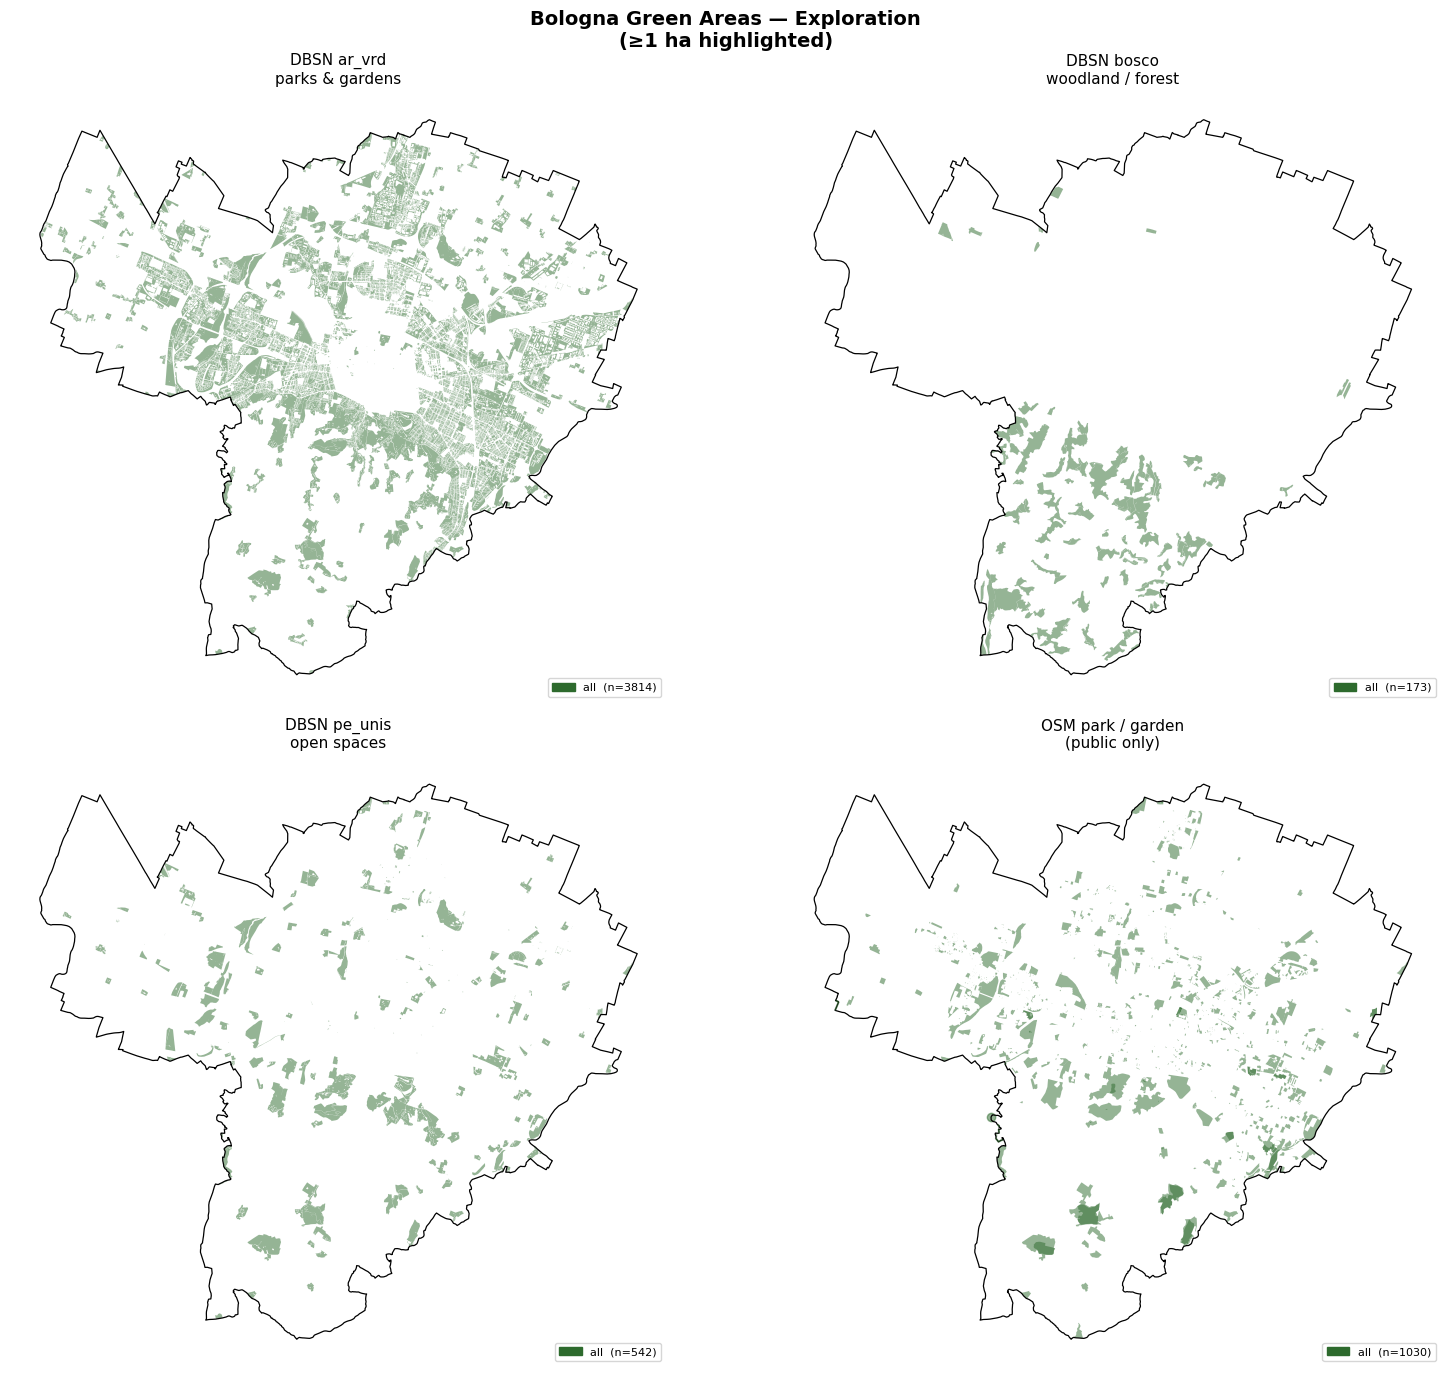

In [13]:

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
fig.suptitle("Bologna Green Areas — Exploration\n(≥1 ha highlighted)", fontsize=14, fontweight="bold")

panels = [
    (av_green_areas, "DBSN ar_vrd\nparks & gardens"),
    (forest,   "DBSN bosco\nwoodland / forest"),
    (green_areas, "DBSN pe_unis\nopen spaces"),
    (osm_parks,  "OSM park / garden\n(public only)"),
]

colors_all = "#2d6a2d"

for ax, (all_gdf, title) in zip(axes.flat, panels):
    boundary.boundary.plot(ax=ax, color="black", linewidth=0.9)
    if len(all_gdf) > 0:
        all_gdf.plot(ax=ax, color=colors_all, alpha=0.5)
    
    patch_all  = mpatches.Patch(color=colors_all,  label=f"all  (n={len(all_gdf)})")
    ax.legend(handles=[patch_all], fontsize=8, loc="lower right")
    ax.set_title(title, fontsize=11)
    ax.set_axis_off()

plt.tight_layout()
plt.savefig("green_areas_exploration.png", dpi=150, bbox_inches="tight")
print("  Saved: green_areas_exploration.png")


In [14]:

# Standardise columns before saving
def prep_save(gdf, source, layer_type):
    cols = ["geometry", "area_ha"]
    # keep name if present
    for c in ["nome", "name", "descrizione", "NOME", "NAME"]:
        if c in gdf.columns:
            cols.append(c)
            break
    return gdf[cols].assign(source=source, layer_type=layer_type).copy()

layers_to_save = {
    #"forest":   prep_save(forest,      "DBSN", "bosco"),
    "ar_vrd_all":        prep_save(av_green_areas,   "DBSN", "ar_vrd_all"),
    "pe_unis_all":       prep_save(green_areas,     "DBSN", "pe_unis_all"),
    "osm_all_public":    prep_save(osm_parks,     "OSM",  "park_garden_all"),
}

for layer_name, gdf in layers_to_save.items():
    gdf.to_file(OUT_GPKG, layer=layer_name, driver="GPKG")
    print(f" {layer_name:25s}  ({len(gdf):,} features)")



 ar_vrd_all                 (3,814 features)
 pe_unis_all                (542 features)
 osm_all_public             (1,030 features)
